### Test de la classe EvalGame

Vous trouverez ici le test de la classe `EvalGame`.

Plan :
1. Chargement des séries temporelles
2. Instanciation de la stratégie d'investissement
3. Test simple avec `EvalGame.eval()` et sauvegarde/chargement des résultats
4. Test sur toutes les dates avec `EvalGame.evalTime()`
5. Test sur une stratégie et plusieurs séries `EvalGame.evalSeries()`
6. Test sur plusieurs stratégies et une série avec `EvalGame.evalStrategies()`


In [14]:
%run -i "BaseLoader.ipynb"
%run -i "BaseClasses.ipynb"
%run -i "BaseEvalGame.ipynb"
# il est nécessaire d'avoir un fichier "Strategies.ipynb" contenant vos stratégies
%run -i "Strategies.ipynb"

### 1. Chargement des séries temporelles

ADA is available in the source COINCODEX


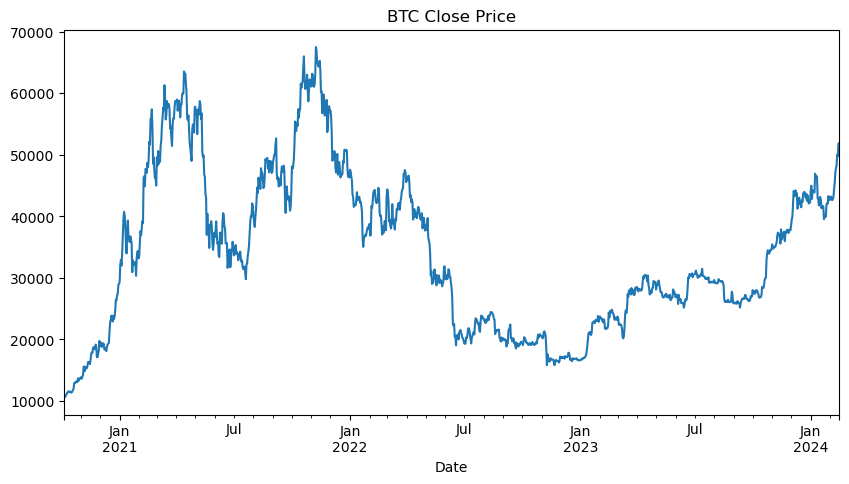

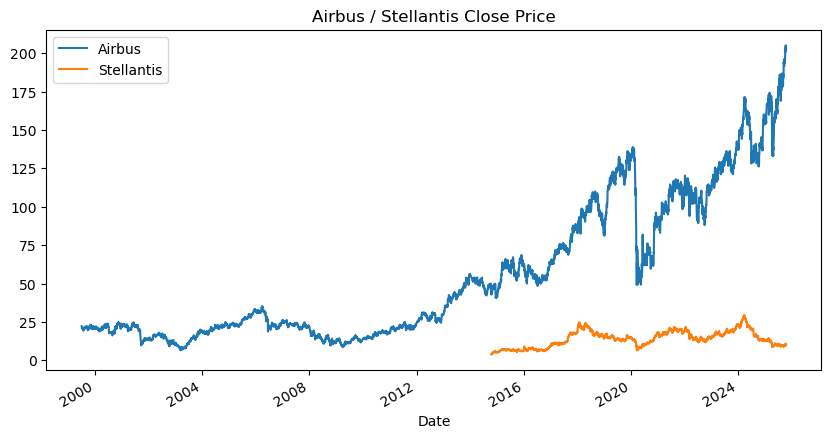

In [2]:
loader = Loader()

loader.loadSource(Loader.COINCODEX, forceEqualDate=True)
loader.loadSource(Loader.NASDAQ, forceEqualDate=True)

if (loader.isAvailable(Loader.COINCODEX, Loader.ADA)):
    print("ADA is available in the source COINCODEX")

dfBitcoin = loader.get(Loader.COINCODEX, Loader.BTC)
dfAirbus = loader.get(Loader.GOOGLE_FINANCE, Loader.AIRBUS)
dfStellantis = loader.get(Loader.GOOGLE_FINANCE, Loader.STELLANTIS)

serieBtc = dfBitcoin.Close
serieAirbus = dfAirbus.Close
serieStellantis = dfStellantis.Close

serieBtc.plot(title="BTC Close Price", figsize=(10, 5), legend=False)
fig, ax = plt.subplots()
serieAirbus.plot(figsize=(10, 5), legend=False, ax=ax)
serieStellantis.plot(title="Airbus / Stellantis Close Price", figsize=(10, 5), legend=False, ax=ax)
ax.legend(["Airbus", "Stellantis"])
plt.show()

### 2. Choix de la stratégie

In [3]:
strategy = StrategyInvest()

### 3. Test simple avec `EvalGame.eval()`

Evaluation d'une série et d'une stratégie en partant de $t_0$

In [4]:
evalGame = EvalGame(100)

results = evalGame.eval(serieBtc, data=None, strategy=strategy, iteration=10, debug=False)

results

([np.float64(3383.438811547857)], [4200])

### 4. Test sur toutes les dates avec `EvalGame.evalTime()`

Evaluation d'une série et d'une stratégie en partant de chaque $t_i$

In [5]:

evalGame = EvalGame(100)

results = evalGame.evalTime(serieBtc, data=None, strategy=strategy, iteration=10, debug=False)

results.head()

,gain,cashInvest
Date,,
2020-10-05,3383.438812,4200.0
2020-10-06,3391.615686,4200.0
2020-10-07,3388.826016,4200.0
2020-10-08,3378.411389,4200.0
2020-10-09,3371.199021,4200.0


### Save the results

In [6]:
EvalGame.saveResults(results, strategy.getName(), Loader.STELLANTIS)

### Load the results

In [7]:
results = EvalGame.loadResults(strategy.getName(), Loader.STELLANTIS)
results.head()

,gain,cashInvest
Date,,
2020-10-05,3383.438812,4200.0
2020-10-06,3391.615686,4200.0
2020-10-07,3388.826016,4200.0
2020-10-08,3378.411389,4200.0
2020-10-09,3371.199021,4200.0


### 5. Evaluation d'une stratégie sur plusieurs series :

In [15]:

evalGame = EvalGame(100)

results = evalGame.evalSeries([serieAirbus, serieStellantis], datas=None, strategy=strategy, iteration=10, debug=False)


In [16]:
results[0].head()

,gain,cashInvest
Date,,
1999-07-01,191997.477367,31600.0
1999-07-02,192001.621104,31600.0
1999-07-05,192014.280409,31600.0
1999-07-06,192036.171695,31600.0
1999-07-07,192059.115447,31600.0


In [22]:
results[1].head()

,gain,cashInvest
Date,,
2014-10-13,-2040.640263,13300.0
2014-10-14,-2040.640263,13300.0
2014-10-15,-2040.640263,13300.0
2014-10-16,-2040.640263,13300.0
2014-10-17,-2040.640263,13300.0


### 6. Evaluation de plusieurs stratégies sur une même série :

In [30]:

evalGame = EvalGame(100)

strategyInvest = StrategyInvest(name="Invest All")
strategy = StrategyInvest(name="Invest Half")

gains, cashInvests = evalGame.evalStrategies(serieStellantis, data=None, strategies=[strategy, strategyInvest], iteration=0, debug=False)



In [31]:
gains.head()

,Invest Half,Invest All
Date,,
2014-10-13,-1885.884479,-1885.884479
2014-10-14,-2040.640263,-2040.640263
2014-10-15,-2040.640263,-2040.640263
2014-10-16,-2040.640263,-2040.640263
2014-10-17,-2040.640263,-2040.640263


In [32]:
cashInvests.head()

,Invest Half,Invest All
Date,,
2014-10-13,13400.0,13400.0
2014-10-14,13300.0,13300.0
2014-10-15,13300.0,13300.0
2014-10-16,13300.0,13300.0
2014-10-17,13300.0,13300.0
